# Z′ direct-search exclusions — observed 95% CL, K = 1

This notebook replaces interpolation of the **maximum SModelS `result0.r`** with direct queries of the experimental **upper-limit maps**. It reproduces and plots the independent limits from:

| Experiment | SModelS analysis / topology | Cross section compared to its limit |
|---|---|---|
| CMS dijet | `CMS-EXO-19-012` / `TRV1jj` | $\sigma(pp\to Z')\,\mathrm{BR}(Z'\to jj)$ |
| ATLAS dijet | `ATLAS-EXOT-2019-03` / `TRV1jj` | $\sigma(pp\to Z')\,\mathrm{BR}(Z'\to jj)$ |
| ATLAS $t\bar t$ | `ATLAS-EXOT-2018-48` / `TRV1tt` | $\sigma(pp\to Z')\,\mathrm{BR}(Z'\to t\bar t)$ |

All plots use **observed** $r_i=\sigma_i/\sigma_{95,i}$ and **$K=1$**. A point is flagged if *at least one* applicable observed limit satisfies $r_i>1$; this is a union of individual exclusions, not a joint likelihood or a globally combined 95% CL result.

**Important:** Dijet limits and $t\bar t$ limits have different vertical axes. Plot them in separate panels. The script reads `rescaling_report.csv` to retain tiny branching ratios that the old SLHA parser dropped (`dec.br < 0.01`). Missing upper limits remain missing, not zero. The previously tested 0.99% lookup is used *only as a documented fallback for missing ATLAS 1% grid-boundary evaluations*, never to change the physical SLHA widths.

## 1. Configuration

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

# Change these locations if your files are elsewhere.
SMODELS_PICKLE = Path('Zp_narrow_smodels.pcl')
SLHA_DIR = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_narrow_SLHAs')
REPORT_CSV = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_SLHAs_ref') / 'rescaling_report.csv'
OUTPUT_DIR = Path('zprime_limits_K1')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DB_PATH = 'official'   # Ensure this is the SAME database as used for the original SModelS run.
K_FACTOR = 1.0
WIDTH_TARGET = 0.01
WIDTH_TOL = 1e-7
INTERIOR_WIDTH_FRACTION = 0.0099

# Select one regime to plot; set to None for every scanned parameter point.
PLOT_REGIME = 'topDom'   # 'topDom', 'jetDom', or None
DOMINANCE_MARGIN = 1.0

ANALYSES = {
    'CMS-EXO-19-012':   dict(tx='TRV1jj', channel='jj', short='CMS dijet', color='tab:blue',  interior_fallback=False),
    'ATLAS-EXOT-2019-03': dict(tx='TRV1jj', channel='jj', short='ATLAS dijet', color='tab:red', interior_fallback=True),
    'ATLAS-EXOT-2018-48': dict(tx='TRV1tt', channel='tt', short=r'ATLAS $t\bar t$', color='tab:purple', interior_fallback=True),
}

assert K_FACTOR == 1.0, 'This notebook is intentionally for uncorrected LO (K=1) results.'
print('SModelS pickle:', SMODELS_PICKLE.resolve())
print('SLHA report:', REPORT_CSV)
print('Output directory:', OUTPUT_DIR.resolve())

SModelS pickle: /home/vinicius/EFT_ToyModel/Z_prime_constraints/Zp_narrow_smodels.pcl
SLHA report: /home/vinicius/EFT_ToyModel/processFolders/Zp_SLHAs_ref/rescaling_report.csv
Output directory: /home/vinicius/EFT_ToyModel/Z_prime_constraints/zprime_limits_K1


## 2. Load the new scan and validate it

`rescaling_report.csv` is the **source of the complete branching ratios and production cross sections** for each corrected SLHA. The SModelS pickle supplies the experimental output. An exact `filename` join ensures we do not mix old and new scan points. We check the mass, width and production cross section against the SModelS parse.

In [16]:
if not SMODELS_PICKLE.is_file():
    raise FileNotFoundError(f'SModelS results missing: {SMODELS_PICKLE}')
if not REPORT_CSV.is_file():
    raise FileNotFoundError(f'Missing {REPORT_CSV}. Use the report generated by the corrected SLHA rescaler.')

smodelsDF = pd.read_pickle(SMODELS_PICKLE)
smodelsDF = smodelsDF[smodelsDF['filename'].astype(str).str.endswith('.slha')].copy()
if smodelsDF['filename'].duplicated().any():
    raise ValueError('Duplicate SLHA names in SModelS pickle; inspect the original aggregation.')

report = pd.read_csv(REPORT_CSV)
required_report = {'filename', 'mass_GeV', 'width_fraction', 'gq', 'gt', 'regime',
                   'sigma_prod_pb', 'sigma_tt_pb', 'sigma_jj_pb', 'br_tt', 'br_jj'}
missing_columns = required_report - set(report.columns)
if missing_columns:
    raise KeyError(f'Missing expected columns in the rescaling report: {sorted(missing_columns)}')
if report['filename'].duplicated().any():
    raise ValueError('Duplicate filenames in rescaling_report.csv')

points = smodelsDF.merge(report, on='filename', how='left', validate='one_to_one', indicator=True)
not_in_report = points['_merge'] != 'both'
if not_in_report.any():
    print(points.loc[not_in_report, 'filename'].head(15).to_string(index=False))
    raise ValueError(f'{not_in_report.sum()} SModelS rows do not correspond to files in the current report. '
                     'Check whether the pickle and SLHA folder belong to the same scan.')
points.drop(columns='_merge', inplace=True)

mass = pd.to_numeric(points['mass.5000001'], errors='coerce')
width = pd.to_numeric(points['width.5000001'], errors='coerce')
report_mass = pd.to_numeric(points['mass_GeV'], errors='coerce')
ratio = width / mass
bad_mass = ~(np.isfinite(mass) & np.isclose(mass, report_mass, rtol=0, atol=1e-6))
bad_width = ~(np.isfinite(ratio) & np.isclose(ratio, WIDTH_TARGET, rtol=0, atol=WIDTH_TOL))
if bad_mass.any() or bad_width.any():
    display(points.loc[bad_mass | bad_width, ['filename', 'mass.5000001', 'mass_GeV', 'width.5000001']].head(15))
    raise ValueError(f'Mass mismatches: {bad_mass.sum()}; width mismatches: {bad_width.sum()}')

points['mass_GeV'] = mass.astype(float)
points['sigma_tt_pb'] = pd.to_numeric(points['sigma_tt_pb'], errors='coerce')
points['sigma_jj_pb'] = pd.to_numeric(points['sigma_jj_pb'], errors='coerce')
points['gq'] = pd.to_numeric(points['gq'], errors='coerce')
points['gt'] = pd.to_numeric(points['gt'], errors='coerce')
if points[['sigma_tt_pb', 'sigma_jj_pb']].isna().any().any():
    raise ValueError('Some physical cross sections are missing from the rescaling report.')

# Optional normalization cross-check against the XS in the SModelS pickle (which is stored in fb).
if 'xsec13TeV(fb).5000001' in points:
    sigma_parsed = pd.to_numeric(points['xsec13TeV(fb).5000001'], errors='coerce') / 1000.0
    mask = sigma_parsed.notna() & (sigma_parsed > 0)
    err = ((sigma_parsed[mask] - points.loc[mask, 'sigma_prod_pb']).abs()
           / points.loc[mask, 'sigma_prod_pb'].replace(0, np.nan))
    print(f'Production XS comparison: {mask.sum()} rows; maximum relative discrepancy = {err.max():.3g}')
    if (err > 2e-3).any():
        raise ValueError('Production XS in SModelS pickle and SLHA rescaling report disagree by >0.2%.')

print(f'Validated points: {len(points)}; distinct masses: {points.mass_GeV.nunique()}')
print('Regimes:', points['regime'].value_counts().to_dict())
print('Small BR(tt) values preserved:', int((points['br_tt'] < 0.01).sum()))
print('Small BR(jj) values preserved:', int((points['br_jj'] < 0.01).sum()))

Production XS comparison: 6020 rows; maximum relative discrepancy = 9.85e-13
Validated points: 6020; distinct masses: 43
Regimes: {'topDom': 3121, 'jetDom': 2899}
Small BR(tt) values preserved: 1450
Small BR(jj) values preserved: 1450


## 3. Read the three experimental upper-limit maps

The `tx.transformPoint(...)` call is essential for SModelS 3.1.1: it transforms the physical mass and width to the grid coordinates. For ATLAS, query exactly 1% **first** and only use 0.99% if the exact query returns `None`. This fallback was independently checked at your benchmark masses; it is **not extrapolation to otherwise unsupported masses**. Every fallback use is recorded in the CSV.

In [17]:
from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, fb

db = Database(DB_PATH)
tx_map = {}
for aid, cfg in ANALYSES.items():
    results = db.getExpResults(analysisIDs=[aid])
    if len(results) != 1:
        raise RuntimeError(f'Expected one database result for {aid}, got {len(results)}')
    candidates = [tx for tx in results[0].getTxNames() if tx.txName == cfg['tx']]
    if len(candidates) != 1:
        raise RuntimeError(f'Cannot uniquely identify topology {cfg["tx"]} for {aid}')
    tx = candidates[0]
    grid_coords = [item[1] for _, item in sorted(tx.dataMap.items())]
    if grid_coords != ['mass', 'totalwidth']:
        raise RuntimeError(f'Unexpected dataMap for {aid}: {tx.dataMap}')
    tx_map[aid] = tx
    print(aid, cfg['tx'], tx.dataMap)

def query_observed_ul(aid, mass_gev, relative_width):
    tx = tx_map[aid]
    physical_coordinates = [float(mass_gev)*GeV, float(mass_gev)*relative_width*GeV]
    transformed_coordinates = tx.transformPoint(physical_coordinates)
    ul = tx.getULFor(sms=None, mass=transformed_coordinates)
    if ul is None:
        return np.nan
    value = float(ul.asNumber(fb))
    return value if np.isfinite(value) and value > 0 else np.nan

mass_grid = np.sort(points['mass_GeV'].unique())
limit_rows = []
for aid, cfg in ANALYSES.items():
    for m in mass_grid:
        exact = query_observed_ul(aid, m, WIDTH_TARGET)
        ul = exact
        method = 'exact_1pct' if np.isfinite(exact) else 'unavailable'
        fraction_used = WIDTH_TARGET if np.isfinite(exact) else np.nan
        if not np.isfinite(exact) and cfg['interior_fallback']:
            interior = query_observed_ul(aid, m, INTERIOR_WIDTH_FRACTION)
            if np.isfinite(interior):
                ul = interior
                method = 'interior_0p99pct'
                fraction_used = INTERIOR_WIDTH_FRACTION
        limit_rows.append(dict(analysis=aid, label=cfg['short'], channel=cfg['channel'],
                               mass_GeV=float(m), ul_fb=ul,
                               ul_pb=ul/1000.0 if np.isfinite(ul) else np.nan,
                               ul_exact_fb=exact, method=method,
                               lookup_width_fraction=fraction_used))

limitsDF = pd.DataFrame(limit_rows)
limitsDF.to_csv(OUTPUT_DIR / 'observed_upper_limits_K1.csv', index=False)
print('\nUpper-limit map coverage:')
print(limitsDF.groupby(['analysis', 'method']).size().to_string())
print('\nKnown mass checks:')
display(limitsDF[limitsDF['mass_GeV'].isin([2300, 2400, 2500, 3000, 3100])]
        .pivot(index='mass_GeV', columns='analysis', values='ul_fb'))

# Sanity check: reproduce the original known ATLAS tt limit at 2300 GeV.
check = limitsDF.query('analysis == "ATLAS-EXOT-2018-48" and mass_GeV == 2300')['ul_fb']
if len(check) and not np.isclose(check.iloc[0], 11.9574, rtol=2e-4):
    print('WARNING: ATLAS tt limit at 2300 GeV differs from 11.9574 fb. Check database version.')

CMS-EXO-19-012 TRV1jj {0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2019-03 TRV1jj {0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2018-48 TRV1tt {0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}

Upper-limit map coverage:
analysis            method          
ATLAS-EXOT-2018-48  exact_1pct          16
                    interior_0p99pct    17
                    unavailable         10
ATLAS-EXOT-2019-03  exact_1pct          12
                    interior_0p99pct     9
                    unavailable         22
CMS-EXO-19-012      exact_1pct          33
                    unavailable         10

Known mass checks:


analysis,ATLAS-EXOT-2018-48,ATLAS-EXOT-2019-03,CMS-EXO-19-012
mass_GeV,,,
2300.0,11.95740,37.6982,29.9416
2400.0,10.63780,37.6588,33.2705
2500.0,8.35983,37.6194,44.1199
3000.0,7.51606,16.4954,56.6192
3100.0,7.39875,13.3030,44.2013


## 4. Reconstruct each observed $r_i$ and the strongest applicable analysis

The total theoretical cross section is read from the corrected SLHA rescaling report, *not* from `ExptRes.result0.theory prediction`, so missing experimental results do not erase the signal prediction.

$$r_i=\frac{1000\,\sigma^{\mathrm{LO}}_i\,[\mathrm{pb}]}{\sigma^{\mathrm{obs}}_{95,i}\,[\mathrm{fb}]}\,,\qquad K=1.$$

`dominant_analysis` identifies the analysis with the largest observed $r$, **only among those three experimentally applicable maps**. The point is marked excluded when the largest is greater than 1. Missing constraints are never replaced with $r=0$.

In [18]:
r_columns = []
for aid, cfg in ANALYSES.items():
    rcol = f'r_{aid}'
    ulcol = f'ul_fb_{aid}'
    sourcecol = f'lookup_method_{aid}'
    subset = limitsDF.loc[limitsDF.analysis == aid, ['mass_GeV', 'ul_fb', 'method']].rename(
        columns={'ul_fb': ulcol, 'method': sourcecol})
    points = points.merge(subset, on='mass_GeV', how='left', validate='many_to_one')
    xs = 'sigma_tt_pb' if cfg['channel'] == 'tt' else 'sigma_jj_pb'
    points[rcol] = 1000.0 * points[xs] / points[ulcol]
    points.loc[~np.isfinite(points[rcol]) | (points[ulcol] <= 0), rcol] = np.nan
    r_columns.append(rcol)

r_values = points[r_columns]
points['has_applicable_limit'] = r_values.notna().any(axis=1)
points['r_max_observed_K1'] = r_values.max(axis=1, skipna=True)
points['excluded_observed_K1'] = points['has_applicable_limit'] & (points['r_max_observed_K1'] > 1)
points['dominant_analysis'] = pd.Series(pd.NA, index=points.index, dtype='object')
valid = points['has_applicable_limit']
points.loc[valid, 'dominant_analysis'] = (
    r_values.loc[valid].idxmax(axis=1).str.removeprefix('r_').to_numpy()
)
points['classification'] = np.select(
    [points['excluded_observed_K1'], points['has_applicable_limit']],
    ['excluded', 'not excluded by these limits'], default='no applicable limit'
)
print('Classifications for the entire scan:')
print(points.classification.value_counts().to_string())
print('Dominant excluding analyses:')
print(points.loc[points.excluded_observed_K1, 'dominant_analysis'].value_counts().to_string())

# Compare with any SModelS originally reported r values (diagnostic only).
reported_r = [c for c in points if c.startswith('ExptRes.result') and c.endswith('.r')]
if reported_r:
    points['r_max_reported_SModelS'] = points[reported_r].apply(pd.to_numeric, errors='coerce').max(axis=1)
    updated = points['r_max_observed_K1'] > points['r_max_reported_SModelS'].fillna(-np.inf) + 1e-8
    print(f'Points with a stronger reconstructed constraint than the recorded SModelS result: {int(updated.sum())}')

# For a fixed regime, select the identical points for all later figures.
def select_regime(df, regime=PLOT_REGIME):
    if regime is None:
        return df.copy()
    if regime not in ('topDom', 'jetDom'):
        raise ValueError("PLOT_REGIME must be 'topDom', 'jetDom', or None")
    mask = df.regime.eq(regime)
    if regime == 'topDom':
        mask &= df['gt'] > DOMINANCE_MARGIN * df['gq']
    else:
        mask &= df['gq'] > DOMINANCE_MARGIN * df['gt']
    return df.loc[mask].copy()

selected = select_regime(points)
print(f'Selected {PLOT_REGIME or "all regimes"}: {len(selected)} points')

Classifications for the entire scan:
classification
not excluded by these limits    3277
excluded                        1763
no applicable limit              980
Dominant excluding analyses:
dominant_analysis
ATLAS-EXOT-2019-03    1283
ATLAS-EXOT-2018-48     368
CMS-EXO-19-012         112
Points with a stronger reconstructed constraint than the recorded SModelS result: 2972
Selected topDom: 3121 points


## 5. The three individual observed 95% CL upper-limit curves

The **CMS and ATLAS dijet curves** share a $\sigma\mathrm{BR}_{jj}$ axis. The **ATLAS $t\bar t$ curve** must have a separate $\sigma\mathrm{BR}_{t\bar t}$ axis. Hollow markers denote a recovered 0.99% interior lookup; filled markers denote exact 1% lookup. A missing grid value is a gap, not an allowed or excluded point.

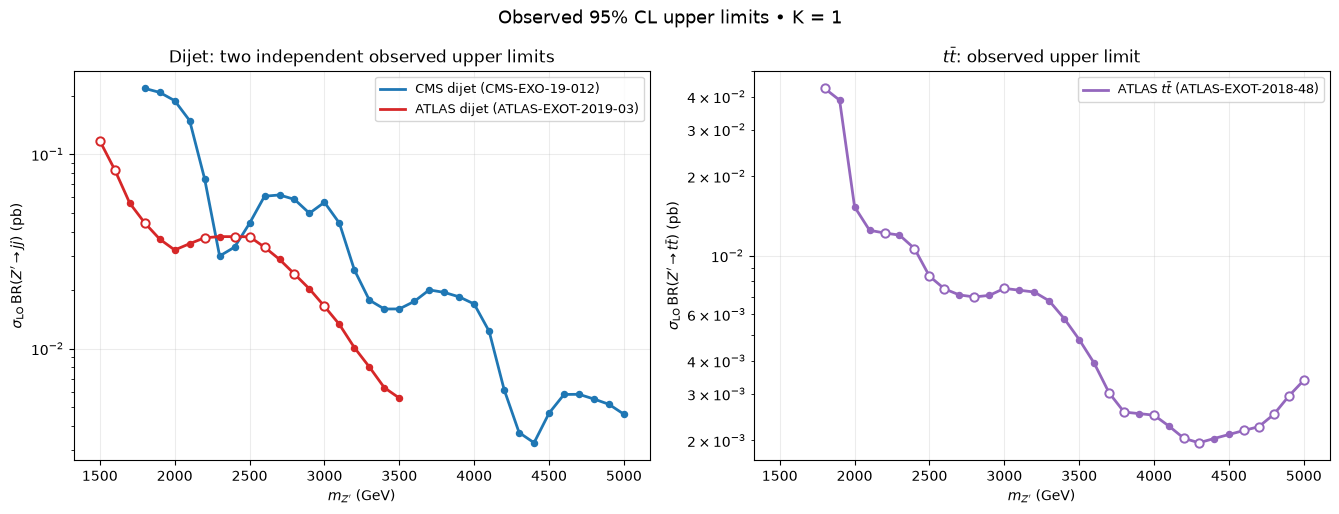

In [19]:
def format_axis(ax, ylabel, title=None):
    ax.set_yscale('log')
    ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)')
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    ax.grid(alpha=0.23, which='major')

fig, (ax_jj, ax_tt) = plt.subplots(1, 2, figsize=(13.5, 5.2), sharex=True)
for aid, cfg in ANALYSES.items():
    limit = limitsDF.loc[limitsDF.analysis == aid].sort_values('mass_GeV')
    ax = ax_tt if cfg['channel'] == 'tt' else ax_jj
    ax.plot(limit.mass_GeV, limit.ul_pb, color=cfg['color'], lw=2,
            label=f'{cfg["short"]} ({aid})')
    exact = limit[limit.method == 'exact_1pct']
    fallback = limit[limit.method == 'interior_0p99pct']
    ax.scatter(exact.mass_GeV, exact.ul_pb, s=19, color=cfg['color'], zorder=3)
    if len(fallback):
        ax.scatter(fallback.mass_GeV, fallback.ul_pb, s=36, facecolors='white',
                   edgecolors=cfg['color'], linewidths=1.4, zorder=4)

format_axis(ax_jj, r'$\sigma_{\mathrm{LO}}\,\mathrm{BR}(Z^\prime\to jj)$ (pb)',
            'Dijet: two independent observed upper limits')
format_axis(ax_tt, r'$\sigma_{\mathrm{LO}}\,\mathrm{BR}(Z^\prime\to t\bar t)$ (pb)',
            r'$t\bar t$: observed upper limit')
for ax in (ax_jj, ax_tt):
    ax.legend(fontsize=9)
fig.suptitle('Observed 95% CL upper limits • K = 1', fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'observed_limits_three_analyses.png', dpi=240, bbox_inches='tight')
plt.show()

## 6. Scan points, colored by the strongest excluding analysis

Each point uses the **maximum of the reconstructed observed** $r_i$ values. Gray means not excluded **by these available tests**; black crosses mean no usable limit was returned. This plot does not interpolate through missing results.

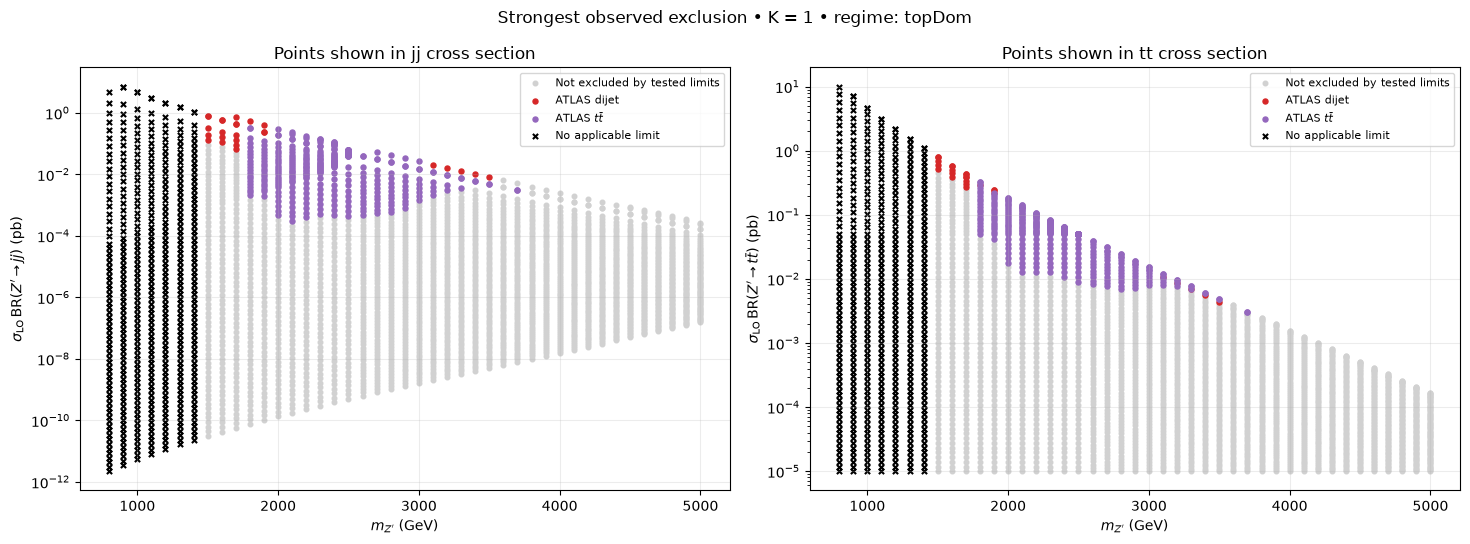

In [24]:
def plot_classified_points(df, savepath=None):
    fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.5), sharex=True)
    info = [('sigma_jj_pb', 'jj', r'$\sigma_{\mathrm{LO}}\,\mathrm{BR}(Z^\prime\to jj)$ (pb)'),
            ('sigma_tt_pb', 'tt', r'$\sigma_{\mathrm{LO}}\,\mathrm{BR}(Z^\prime\to t\bar t)$ (pb)')]
    for ax, (sigma_col, channel, ylabel) in zip(axes, info):
        good = df[sigma_col].gt(0)
        allowed = df.loc[good & df.has_applicable_limit & ~df.excluded_observed_K1]
        unknown = df.loc[good & ~df.has_applicable_limit]
        ax.scatter(allowed.mass_GeV, allowed[sigma_col], s=11, c='0.82',
                   label='Not excluded by tested limits', rasterized=True)
        for aid, cfg in ANALYSES.items():
            sub = df.loc[good & df.excluded_observed_K1 & df.dominant_analysis.eq(aid)]
            if len(sub):
                ax.scatter(sub.mass_GeV, sub[sigma_col], s=13, color=cfg['color'],
                           label=cfg['short'], rasterized=True)
        if len(unknown):
            ax.scatter(unknown.mass_GeV, unknown[sigma_col], marker='x', s=14,
                       c='black', label='No applicable limit', rasterized=True)
        format_axis(ax, ylabel, title=f'Points shown in {channel} cross section')
        ax.legend(loc='upper right', fontsize=8)
    fig.suptitle(f'Strongest observed exclusion • K = 1 • regime: {PLOT_REGIME or "all"}')
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=240, bbox_inches='tight')
    plt.show()

plot_classified_points(selected, OUTPUT_DIR / f'classified_points_{PLOT_REGIME or "all"}_K1.png')

## 7. Three separate analysis panels: scan points **and** each exclusion curve

For each experimental analysis, points **above** its observed limit are excluded by that analysis alone. Each panel uses the cross section appropriate to that channel, so the curves are not artificially projected from $jj$ to $t\bar t$ (or vice versa).

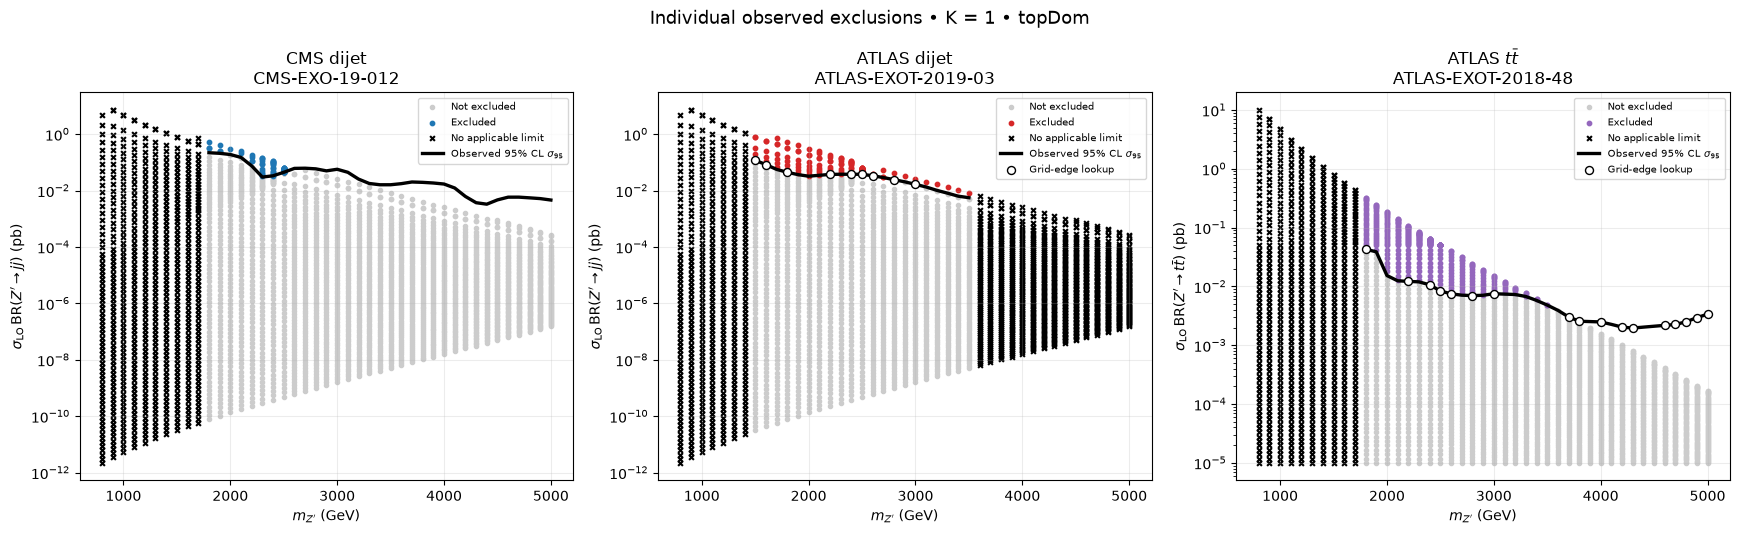

In [21]:
def plot_per_analysis_panels(df, savepath=None):
    fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.4), sharex=True)
    for ax, (aid, cfg) in zip(axes, ANALYSES.items()):
        sigma_col = 'sigma_tt_pb' if cfg['channel'] == 'tt' else 'sigma_jj_pb'
        r_col = f'r_{aid}'
        valid_sigma = df[sigma_col].gt(0)
        has_limit = df[r_col].notna()
        allowed = df.loc[valid_sigma & has_limit & df[r_col].le(1)]
        excluded = df.loc[valid_sigma & has_limit & df[r_col].gt(1)]
        unknown = df.loc[valid_sigma & ~has_limit]
        ax.scatter(allowed.mass_GeV, allowed[sigma_col], s=9, c='0.8',
                   label='Not excluded', rasterized=True)
        ax.scatter(excluded.mass_GeV, excluded[sigma_col], s=10,
                   c=cfg['color'], label='Excluded', rasterized=True)
        if len(unknown):
            ax.scatter(unknown.mass_GeV, unknown[sigma_col], s=12, c='black',
                       marker='x', label='No applicable limit', rasterized=True)
        lim = limitsDF.loc[limitsDF.analysis == aid].sort_values('mass_GeV')
        ax.plot(lim.mass_GeV, lim.ul_pb, lw=2.4, color='black', label=r'Observed 95% CL $\sigma_{95}$')
        fallback = lim[lim.method == 'interior_0p99pct']
        if len(fallback):
            ax.scatter(fallback.mass_GeV, fallback.ul_pb, s=33, facecolors='white',
                       edgecolors='black', label='Grid-edge lookup', zorder=5)
        channel_tex = r't\bar t' if cfg['channel'] == 'tt' else 'jj'
        ylabel = (r'$\sigma_{\mathrm{LO}}\,\mathrm{BR}(Z^\prime\to '
                  + channel_tex + r')$ (pb)')
        format_axis(ax, ylabel, title=f'{cfg["short"]}\n{aid}')
        ax.legend(fontsize=7.5, loc='upper right')
    fig.suptitle(f'Individual observed exclusions • K = 1 • {PLOT_REGIME or "all regimes"}', fontsize=13)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=240, bbox_inches='tight')
    plt.show()

plot_per_analysis_panels(selected, OUTPUT_DIR / f'per_analysis_points_and_curves_{PLOT_REGIME or "all"}_K1.png')

## 8. Validate against the individual results SModelS actually reported

When SModelS stored a result for an analysis, its $r$ should agree with the reconstructed one up to rounding or topology-specific details. This check looks across **all** available `ExptRes.resultN` columns, rather than assuming only `result0` exists.

In [22]:
import re
indices = sorted({int(match.group(1)) for col in selected.columns
                  if (match := re.fullmatch(r'ExptRes\.result(\d+)\.AnalysisID', col))})
compare_rows = []
for i in indices:
    ana_col, observed_col = f'ExptRes.result{i}.AnalysisID', f'ExptRes.result{i}.r'
    if observed_col not in selected:
        continue
    for aid in ANALYSES:
        match = selected[ana_col].eq(aid)
        if not match.any():
            continue
        reported = pd.to_numeric(selected.loc[match, observed_col], errors='coerce')
        rebuilt = pd.to_numeric(selected.loc[match, f'r_{aid}'], errors='coerce')
        valid = (reported > 0) & (rebuilt > 0)
        if valid.any():
            rel = ((reported[valid] - rebuilt[valid]).abs() / reported[valid])
            compare_rows.append(dict(analysis=aid, n=len(rel),
                                     max_relative_difference=rel.max(),
                                     median_relative_difference=rel.median()))
if compare_rows:
    comparison = pd.DataFrame(compare_rows).groupby('analysis', as_index=False).agg(
        n=('n', 'sum'), max_relative_difference=('max_relative_difference', 'max'),
        median_relative_difference=('median_relative_difference', 'median'))
    display(comparison)
else:
    print('No comparable original per-analysis result columns found.')

,analysis,n,max_relative_difference,median_relative_difference
0,ATLAS-EXOT-2018-48,1157,4.936529e-07,5.652447e-08
1,ATLAS-EXOT-2019-03,751,4.891094e-07,6.694894e-08
2,CMS-EXO-19-012,2227,4.659026e-07,7.125986e-08


## 9. Export the complete result

The key CSVs contain **each separate experimental observed limit** and **each scan point's per-analysis $r_i$**. These are preferable to a contour obtained by interpolating `ExptRes.result0.r` across distinct analyses. The plotted observed limit curves are exactly the values saved in `observed_upper_limits_K1.csv`.

In [23]:
cols = ['filename', 'mass_GeV', 'width.5000001', 'width_fraction', 'regime',
        'gq', 'gt', 'sigma_prod_pb', 'sigma_jj_pb', 'sigma_tt_pb',
        'br_jj', 'br_tt', 'r_max_observed_K1', 'has_applicable_limit',
        'excluded_observed_K1', 'dominant_analysis', 'classification']
for aid in ANALYSES:
    cols += [f'ul_fb_{aid}', f'lookup_method_{aid}', f'r_{aid}']
cols = [c for c in cols if c in points]
points[cols].to_csv(OUTPUT_DIR / 'classified_scan_points_K1.csv', index=False)
selected[cols].to_csv(OUTPUT_DIR / f'classified_scan_points_{PLOT_REGIME or "all"}_K1.csv', index=False)

print('\nFiles written:')
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f'  {path} ({path.stat().st_size:,} bytes)')
print('\nNOTE: These curves are for K=1. To study K>1, multiply theoretical r values, '
      'but keep the experimental observed UL curves unchanged.')


Files written:
  zprime_limits_K1/classified_points_topDom_K1.png (368,594 bytes)
  zprime_limits_K1/classified_scan_points_K1.csv (2,177,937 bytes)
  zprime_limits_K1/classified_scan_points_topDom_K1.csv (1,157,214 bytes)
  zprime_limits_K1/observed_limits_three_analyses.png (256,992 bytes)
  zprime_limits_K1/observed_upper_limits_K1.csv (9,846 bytes)
  zprime_limits_K1/per_analysis_points_and_curves_topDom_K1.png (494,991 bytes)

NOTE: These curves are for K=1. To study K>1, multiply theoretical r values, but keep the experimental observed UL curves unchanged.
